# 1. Dataset Loading and Initial Inspection

This section loads the final supervised dataset and examines its
basic structure, columns, data types, missing values and duplicate records.

In [1]:
# Import the libraries required for dataset inspection and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure the default visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Load the final supervised dataset prepared in Notebook 02
df = pd.read_csv("../data/interim/civicsense_supervised_dataset.csv")

# Display the first five records
df.head()

,model_text,target_category,source_dataset
0,Sadak paar karne wala concrete ka puliya adhur...,Road Infrastructure,Dataset_A_Multilingual
1,"सीएमसी का पानी जारी नहीं किया जा रहा है, वे बा...",Water Supply,Dataset_A_Multilingual
2,Garbage dump all over,Waste Management,Dataset_A_Multilingual
3,Puttenahalli jheel road jo Arekere ki or jaati...,Road Infrastructure,Dataset_A_Multilingual
4,Desilted Mud is not cleared making the road di...,Waste Management,Dataset_A_Multilingual


In [2]:
# Check the number of records and columns
print("Dataset Shape:", df.shape)

# Inspect column names, data types and non-null counts
df.info()

# Check the number of missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

# Check for duplicate complaint texts
print("\nDuplicate Model Texts:", df["model_text"].duplicated().sum())

# Check the number of unique target categories
print("\nUnique Categories:", df["target_category"].nunique())

# Display the available target categories
print("\nTarget Categories:")
print(sorted(df["target_category"].unique()))

Dataset Shape: (16519, 3)
<class 'pandas.DataFrame'>
RangeIndex: 16519 entries, 0 to 16518
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   model_text       16519 non-null  str  
 1   target_category  16519 non-null  str  
 2   source_dataset   16519 non-null  str  
dtypes: str(3)
memory usage: 5.2 MB

Missing Values:
model_text         0
target_category    0
source_dataset     0
dtype: int64

Duplicate Model Texts: 0

Unique Categories: 12

Target Categories:
['Animal Management', 'Civic Infrastructure and Encroachment', 'Drainage and Sewerage', 'Electricity and Utilities', 'Environment and Public Spaces', 'Public Safety', 'Public Sanitation', 'Road Infrastructure', 'Street Lighting', 'Traffic and Transport', 'Waste Management', 'Water Supply']


# 2. Target Category Distribution

This section examines the distribution of complaints across the
12 target categories to identify class imbalance and understand
which types of civic complaints are most and least represented.

,Complaint_Count,Percentage
target_category,,
Road Infrastructure,5224,31.62
Waste Management,4235,25.64
Street Lighting,1472,8.91
Traffic and Transport,1159,7.02
Drainage and Sewerage,1006,6.09
Animal Management,868,5.25
Environment and Public Spaces,758,4.59
Water Supply,602,3.64
Public Sanitation,481,2.91


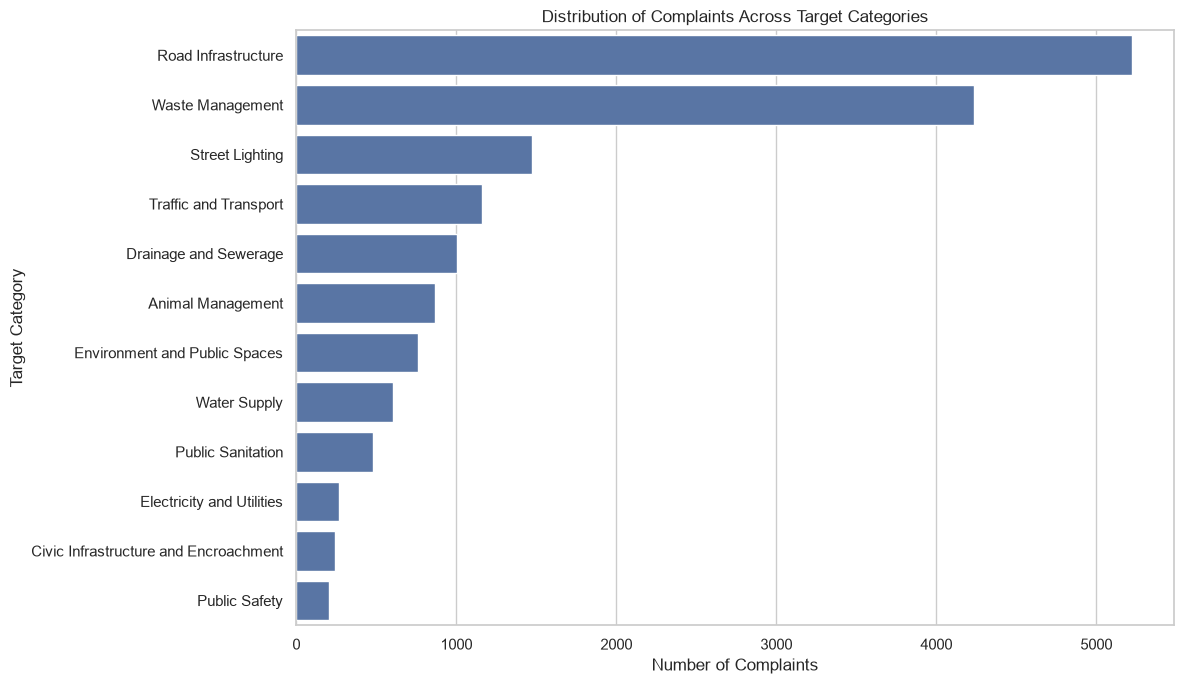

In [4]:
# Calculate the number of complaints in each target category
category_counts = df["target_category"].value_counts()

# Calculate the percentage contribution of each category
category_percentage = (
    df["target_category"].value_counts(normalize=True) * 100
)

# Combine counts and percentages into one summary table
category_distribution = pd.DataFrame({
    "Complaint_Count": category_counts,
    "Percentage": category_percentage.round(2)
})

# Display categories from highest to lowest frequency
display(category_distribution)

# Visualize the category distribution
plt.figure(figsize=(12, 7))

sns.barplot(
    x=category_distribution["Complaint_Count"],
    y=category_distribution.index
)

plt.title("Distribution of Complaints Across Target Categories")
plt.xlabel("Number of Complaints")
plt.ylabel("Target Category")
plt.tight_layout()
plt.show()

### Observations

- Road Infrastructure has the highest representation, accounting for 31.62% of all complaints.
- Waste Management is the second-largest category, contributing 25.64%.
- Together, these two categories represent 57.26% of the dataset.
- Public Safety has the lowest representation, with only 1.23% of complaints.
- The distribution indicates a significant class imbalance, which may affect model performance across different categories.

This imbalance will be considered during model training and evaluation.

# 3. Dataset Source Distribution

This section examines the contribution of each source dataset
to the final supervised dataset. It helps us understand how the
combined dataset is composed and whether one source dominates
the overall collection.

,Complaint_Count,Percentage
source_dataset,,
Dataset_B_English,15296,92.6
Dataset_A_Multilingual,1223,7.4


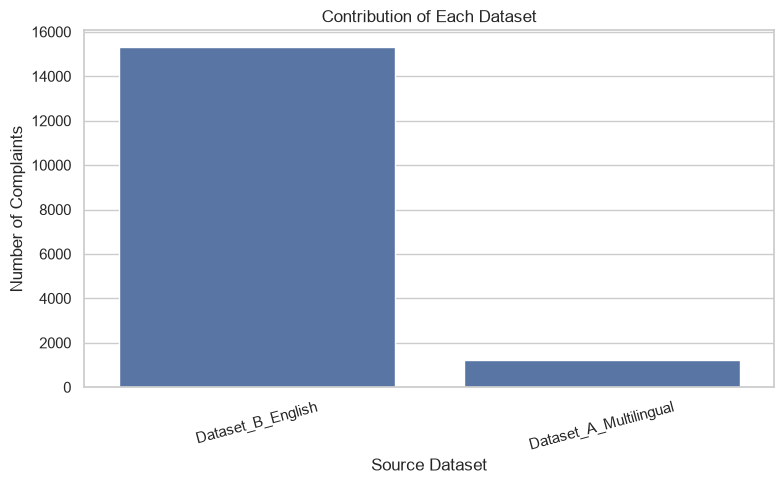

In [5]:
# Count the number of complaints contributed by each dataset
source_counts = df["source_dataset"].value_counts()

# Calculate the percentage contribution of each dataset
source_percentage = df["source_dataset"].value_counts(normalize=True) * 100

# Combine counts and percentages into a summary table
source_distribution = pd.DataFrame({
    "Complaint_Count": source_counts,
    "Percentage": source_percentage.round(2)
})

# Display the source-wise distribution
display(source_distribution)

# Visualize the contribution of each dataset
plt.figure(figsize=(8, 5))

sns.barplot(
    x=source_distribution.index,
    y=source_distribution["Complaint_Count"]
)

plt.title("Contribution of Each Dataset")
plt.xlabel("Source Dataset")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Observations

- Dataset B (English) contributes 15,296 complaints, representing 92.60% of the final dataset.
- Dataset A (Multilingual) contributes 1,223 complaints, representing 7.40%.
- The combined dataset is heavily dominated by English-language data.
- This source imbalance may influence model learning and its performance across different languages.
- Source-wise and language-wise evaluation will therefore be important during model assessment.

# 4. Text Length Analysis

This section examines the length of complaint texts using
character counts and whitespace-separated word counts.

The analysis helps identify variations in complaint length,
very short complaints and unusually long descriptions.

In [6]:
# Calculate the number of characters in each complaint
df["char_length"] = df["model_text"].str.len()

# Calculate whitespace-separated word counts
# Note: This is an approximate word count for multilingual text
df["word_count"] = df["model_text"].str.split().str.len()

# Display the first five records with their calculated lengths
display(df[["model_text", "char_length", "word_count"]].head())

# Generate descriptive statistics for both length measures
display(df[["char_length", "word_count"]].describe())

,model_text,char_length,word_count
0,Sadak paar karne wala concrete ka puliya adhur...,200,37
1,"सीएमसी का पानी जारी नहीं किया जा रहा है, वे बा...",200,38
2,Garbage dump all over,21,4
3,Puttenahalli jheel road jo Arekere ki or jaati...,200,37
4,Desilted Mud is not cleared making the road di...,63,11


,char_length,word_count
count,16519.000000,16519.000000
mean,264.961559,46.509534
std,221.493582,39.107610
min,10.000000,2.000000
25%,129.000000,22.000000
50%,201.000000,37.000000
75%,332.500000,59.000000
max,3778.000000,744.000000


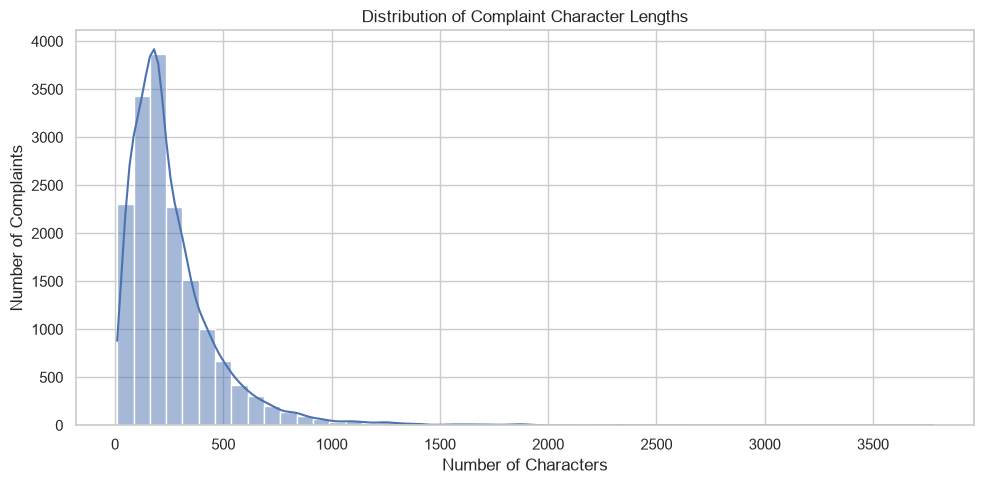

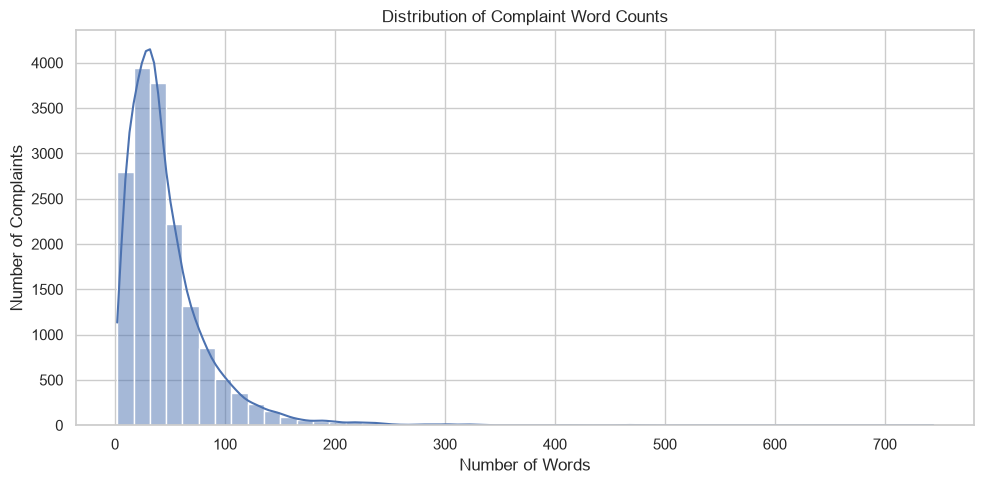

In [7]:
# Plot the distribution of complaint character lengths
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="char_length",
    bins=50,
    kde=True
)

plt.title("Distribution of Complaint Character Lengths")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Complaints")
plt.tight_layout()
plt.show()


# Plot the distribution of whitespace-separated word counts
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=50,
    kde=True
)

plt.title("Distribution of Complaint Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Complaints")
plt.tight_layout()
plt.show()

In [8]:
# Count complaints containing exactly 200 characters
print("Complaints with exactly 200 characters:",
      (df["char_length"] == 200).sum())

# Calculate the percentage of complaints with exactly 200 characters
print("Percentage:",
      round((df["char_length"] == 200).mean() * 100, 2), "%")

# Compare the frequency of 200-character texts across datasets
print("\nSource-wise count of 200-character complaints:")

display(
    df[df["char_length"] == 200]
    ["source_dataset"]
    .value_counts()
    .to_frame("Count")
)

# Inspect some examples to identify whether the text appears cut off
display(
    df.loc[
        df["char_length"] == 200,
        ["model_text", "source_dataset"]
    ].head(10)
)

Complaints with exactly 200 characters: 511
Percentage: 3.09 %

Source-wise count of 200-character complaints:


,Count
source_dataset,
Dataset_A_Multilingual,474
Dataset_B_English,37


,model_text,source_dataset
0,Sadak paar karne wala concrete ka puliya adhur...,Dataset_A_Multilingual
1,"सीएमसी का पानी जारी नहीं किया जा रहा है, वे बा...",Dataset_A_Multilingual
3,Puttenahalli jheel road jo Arekere ki or jaati...,Dataset_A_Multilingual
9,The road opposite to the cantonment railway st...,Dataset_A_Multilingual
10,Nayi Cauvery water pipeline sadak par fit kar ...,Dataset_A_Multilingual
14,From avenue road entrance to mamulpet pedestri...,Dataset_A_Multilingual
15,"Dusri main road, 11th cross Anwar Layout Venka...",Dataset_A_Multilingual
17,"80 ft road, LBS Nagar, Anjanapura BDA Layout\n...",Dataset_A_Multilingual
18,वे सड़कों पर कचरा फेंक रहे हैं और यहां तक कि ग...,Dataset_A_Multilingual
23,In Ramamurthy Nagar sir MV nagar 1st cross roa...,Dataset_A_Multilingual


In [10]:
# Load the original multilingual annotation checkpoint
original_df = pd.read_csv(
    "../data/interim/multilingual_annotation_progress.csv"
)

# Select complaints from Dataset A having exactly 200 characters
sample_a = df[
    (df["source_dataset"] == "Dataset_A_Multilingual") &
    (df["char_length"] == 200)
].head(10)

# Display the complete text and its ending to inspect possible cut-offs
for idx, row in sample_a.iterrows():
    print(f"\nComplaint index: {idx}")
    print("Model text length:", len(row["model_text"]))
    print("Text ending:", repr(row["model_text"][-80:]))

    # Check whether the original description matches the model text
    matches = original_df[
        original_df["description"].astype(str) == row["model_text"]
    ]

    print("Matching original records:", len(matches))

    if not matches.empty:
        print("Original description length:",
              matches["description"].str.len().iloc[0])


Complaint index: 0
Model text length: 200
Text ending: 'ye hain, isse har vaahan ke nichle hisse ko nuksaan pahunch raha hai aur har baa'
Matching original records: 1
Original description length: 200

Complaint index: 1
Model text length: 200
Text ending: '। कार्यकर्ता ने कोई कोविड-19 निवारक उपाय नहीं किए हैं और निरीक्षण के लिए जबरदस्त'
Matching original records: 1
Original description length: 200

Complaint index: 3
Model text length: 200
Text ending: ' gir gaya ya vaahan bahut dheere chal rahe hain. Aur agar bhari barish hoti hai,'
Matching original records: 1
Original description length: 200

Complaint index: 9
Model text length: 200
Text ending: 'bridge is a messy place strewn with construction debris. Car drivers have to nav'
Matching original records: 1
Original description length: 200

Complaint index: 10
Model text length: 200
Text ending: 'f 700 rupaye maang raha hai. Yeh umeed kiya jaane wala vyavhar nahi hai. Vah keh'
Matching original records: 1
Original description length

### Observation: Possible Text Truncation

- A total of 511 complaints (3.09%) contain exactly 200 characters.
- Of these, 474 records belong to Dataset A (Multilingual), while 37 belong to Dataset B (English).
- Inspection of the original annotation checkpoint confirms that these descriptions were already 200 characters before the final model_text preparation.
- Several descriptions end abruptly, suggesting possible truncation during an earlier data collection or processing stage.

These records will be retained in the dataset for now. Their original content should not be artificially reconstructed or modified. The potential truncation will be considered as a limitation of the dataset.

# 5. Text Length Distribution Across Categories

This section compares complaint lengths across the target categories
using word counts. It helps identify differences in the amount of
text available for learning each category.

,count,mean,median,min,max
target_category,,,,,
Public Safety,203,59.79,48.0,3,229
Environment and Public Spaces,758,56.46,44.0,4,382
Animal Management,868,49.81,42.0,3,365
Electricity and Utilities,269,50.90,41.0,5,219
Road Infrastructure,5224,48.03,39.0,2,533
Drainage and Sewerage,1006,50.24,39.0,3,469
Civic Infrastructure and Encroachment,242,48.98,37.5,3,464
Water Supply,602,47.11,37.0,3,333
Waste Management,4235,47.13,37.0,2,744


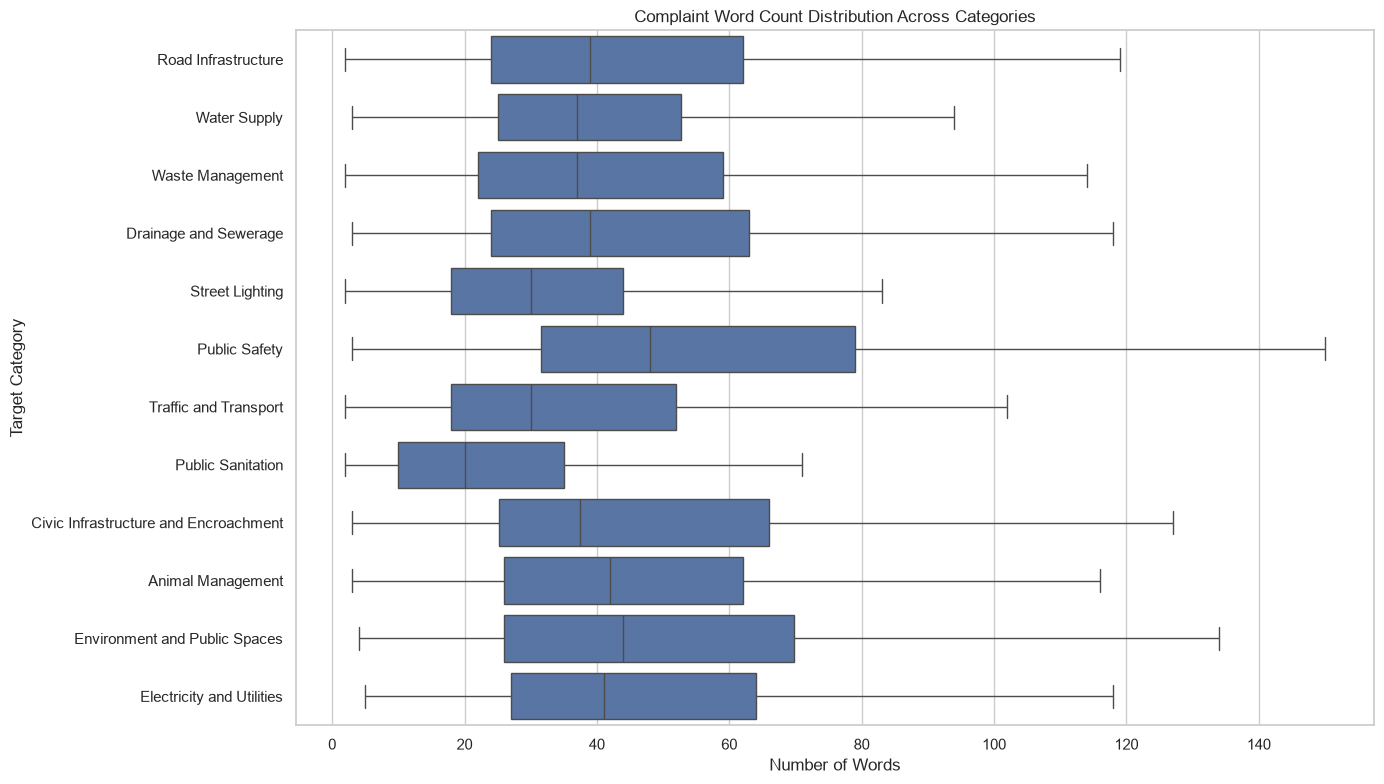

In [9]:
# Calculate word-count statistics separately for each category
category_length_stats = (
    df.groupby("target_category")["word_count"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("median", ascending=False)
)

# Display category-wise complaint length statistics
display(category_length_stats.round(2))

# Compare word-count distributions across categories using a boxplot
plt.figure(figsize=(14, 8))

sns.boxplot(
    data=df,
    x="word_count",
    y="target_category",
    showfliers=False
)

plt.title("Complaint Word Count Distribution Across Categories")
plt.xlabel("Number of Words")
plt.ylabel("Target Category")
plt.tight_layout()
plt.show()

### Observations

- Public Safety has the highest median complaint length, with 48 words.
- Environment and Public Spaces follows with a median of 44 words.
- Public Sanitation has the shortest median complaint length, with 20 words.
- Complaint lengths vary across categories, indicating differences in the amount of information provided by citizens.
- Several categories contain unusually long complaints, resulting in right-skewed word-count distributions.

These variations will be considered when selecting the sequence length during tokenization.

# 6. Short and Long Complaint Inspection

This section examines the shortest and longest complaints in the
dataset. It helps identify variations in complaint descriptions
and understand the textual information available for classification.

In [11]:
# Display the 10 shortest complaints based on word count
shortest_complaints = df.nsmallest(10, "word_count")[
    ["model_text", "target_category", "word_count"]
]

display(shortest_complaints)

,model_text,target_category,word_count
158,कचरा संग्रहण,Waste Management,2
217,सार्वजनिक मूत्रत्याग,Public Sanitation,2
335,Street lights,Street Lighting,2
524,Broken/unusable footpath,Road Infrastructure,2
578,नया शौचालय,Public Sanitation,2
610,सिग्नल उल्लंघन,Traffic and Transport,2
620,बड़ा गड्ढा,Road Infrastructure,2
653,bada gaddha,Road Infrastructure,2
823,Broken footpath,Road Infrastructure,2
895,खराब सड़क।,Road Infrastructure,2


In [12]:
# Display the 10 longest complaints based on word count
longest_complaints = df.nlargest(10, "word_count")[
    ["model_text", "target_category", "word_count"]
]

display(longest_complaints)

,model_text,target_category,word_count
5929,Harassment Done by Garbage Collectors Hi. I am...,Waste Management,744
4904,Road is worst in IT hub Neeladri Road in Elect...,Road Infrastructure,533
4045,Vehicle Horn noise issue My Apartment is facin...,Traffic and Transport,472
6131,"Bad condition of footpaths Hello sir/madam,\n\...",Drainage and Sewerage,469
15224,Road and Park Encroachment There is a peaceful...,Civic Infrastructure and Encroachment,464
2953,Outer ring road is swept but the mud/sand etc ...,Waste Management,459
14275,No road and drainage system for 11 years- Caus...,Drainage and Sewerage,441
1563,Long parking with no movement &amp; circulatio...,Traffic and Transport,414
1990,"BBMP PARK MISUSED, OWNER MISUSE PAVEMENT,VIJAY...",Traffic and Transport,407
9022,"I was a single lady at 9PM, driver and conduct...",Traffic and Transport,404


In [13]:
# Count complaints containing fewer than 10 whitespace-separated words
short_complaint_count = (df["word_count"] < 10).sum()

# Calculate their percentage in the complete dataset
short_complaint_percentage = (
    short_complaint_count / len(df) * 100
)

print("Complaints with fewer than 10 words:", short_complaint_count)
print("Percentage:", round(short_complaint_percentage, 2), "%")

Complaints with fewer than 10 words: 1045
Percentage: 6.33 %


### Observations

- A total of 1,045 complaints (6.33%) contain fewer than 10 words.
- Some short complaints consist of only two words but still communicate identifiable civic issues.
- The longest complaint contains 744 words, showing considerable variation in complaint length.
- Several complaints contain detailed narratives, while others provide only brief descriptions.
- HTML entities, line breaks and formatting variations are also present in some records.

Short complaints will be retained because they may contain useful classification information. Text cleaning and sequence preparation will be addressed in the preprocessing and tokenization stages.

# 7. Key EDA Findings

The exploratory data analysis of the CivicSense supervised dataset
revealed the following findings:

1. The final dataset contains 16,519 complaints across 12 target categories.
2. No missing values or duplicate model_text records were found.
3. Road Infrastructure and Waste Management together account for 57.26% of the dataset.
4. The dataset has a significant class imbalance, with Public Safety having the lowest representation.
5. Dataset B (English) contributes 92.60% of the records, while Dataset A (Multilingual) contributes 7.40%.
6. Complaint lengths are right-skewed, with an average of approximately 47 words and a median of 37 words.
7. A total of 511 complaints contain exactly 200 characters, with most originating from Dataset A. Inspection suggests possible truncation in the original data.
8. Complaint lengths vary across categories. Public Safety has the highest median word count, while Public Sanitation has the lowest.
9. Approximately 6.33% of complaints contain fewer than 10 words.
10. Some records contain HTML entities, line breaks and formatting variations that should be considered during preprocessing.

These findings will guide text preprocessing, tokenization, sequence length selection and model evaluation.